In [52]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import psycopg2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

MY_LOGIN = 'oazimurodov'   
MY_PASSWORD = '#it is expired now.
conn = psycopg2.connect(
    host='thomas.proxy.rlwy.net',
    port=51432,
    dbname='academy_db',
    user=MY_LOGIN,
    password=MY_PASSWORD,
    sslmode='require'
)

def load_data(table_name):
    return pd.read_sql(f"SELECT * FROM {table_name}", conn)

# Load all datasets
transactions = load_data("ds_transactions_2")
cards = load_data("ds_cards")
customers = load_data("ds_customers")
terminals = load_data("ds_terminals_1")
merchants = load_data("ds_merchants_1")
mcc_codes = load_data("ds_merchant_categories")

pd.set_option("display.max_columns", None)
print("Data loaded successfully")
print(f"Transactions: {transactions.shape}, Cards: {cards.shape}, Customers: {customers.shape}")

Data loaded successfully
Transactions: (60320, 11), Cards: (3286, 8), Customers: (2000, 8)


In [53]:
# Data preparation and feature engineering
df = (transactions
      .merge(cards, on="card_id", how="left", suffixes=("", "_card"))
      .merge(customers, on="customer_id", how="left", suffixes=("", "_cust"))
      .merge(merchants, on="merchant_id", how="left", suffixes=("_card", "_merch"))
      .merge(mcc_codes, on="category_id", how="left")
      .merge(terminals, on="terminal_id", how="left", suffixes=("", "_term")))

# Feature engineering
df["is_declined"] = df["decline_reason"].notna()
df["customer_age"] = ((df["txn_ts"] - df["birth_date"]).dt.days / 365.25).round(1)
df["card_age_days"] = (df["txn_ts"] - df["issue_date"]).dt.days
df["customer_tenure_days"] = (df["txn_ts"] - df["onboarding_date"]).dt.days
df["txn_month"] = df["txn_ts"].dt.to_period("M").astype(str)
df["txn_hour"] = df["txn_ts"].dt.hour
df["txn_weekday"] = df["txn_ts"].dt.day_name()

print(f"Dataset shape: {df.shape}")
print(f"Overall decline rate: {df['is_declined'].mean():.2%}")
print(f"Overall dispute rate: {df['is_disputed'].mean():.2%}")

Dataset shape: (60320, 49)
Overall decline rate: 6.10%
Overall dispute rate: 0.33%


In [57]:
# SECTION 1: Customer Segmentation Analysis
print("="*60)
print("1. CUSTOMER  SEGMENT ANALYSIS")
print("="*60)

seg_analysis = df.groupby("customer_segment").agg(
    transactions=("transaction_id", "count"),
    avg_txn_amount=("amount_uzs", "mean"),
    median_txn_amount=("amount_uzs", "median"),
    total_volume=("amount_uzs", "sum"),
    decline_rate=("is_declined", lambda x: (x.sum() / len(x) * 100)),
    dispute_rate=("is_disputed", lambda x: (x.sum() / len(x) * 100)),
).sort_values("transactions", ascending=False)

seg_analysis["market_share_%"] = (seg_analysis["transactions"] / seg_analysis["transactions"].sum() * 100).round(2)
print(seg_analysis.round(2))

1. CUSTOMER  SEGMENT ANALYSIS
                  transactions  avg_txn_amount  median_txn_amount  \
customer_segment                                                    
mass                     31551       210844.21           121400.0   
payroll                  16829       213009.01           120500.0   
premium                   8973       204398.07           118300.0   
student                   2967        97334.24            54200.0   

                  total_volume  decline_rate  dispute_rate  market_share_%  
customer_segment                                                            
mass                6652345800          5.80          0.40           52.31  
payroll             3584728700          5.85          0.24           27.90  
premium             1834063900          5.92          0.25           14.88  
student              288790700         11.19          0.40            4.92  


In [56]:
print("\nChannel mix by segment (%):")
channel_distribution = pd.crosstab(df["customer_segment"], df["entry_mode"], normalize="index") * 100
print(channel_distribution.round(1))


Channel mix by segment (%):
entry_mode        chip  contactless  ecom_cvv  fallback_magstripe
customer_segment                                                 
mass              48.8         26.4      23.6                 1.3
payroll           49.3         25.7      23.7                 1.3
premium           48.5         26.7      23.4                 1.3
student           43.6         23.2      32.3                 1.0


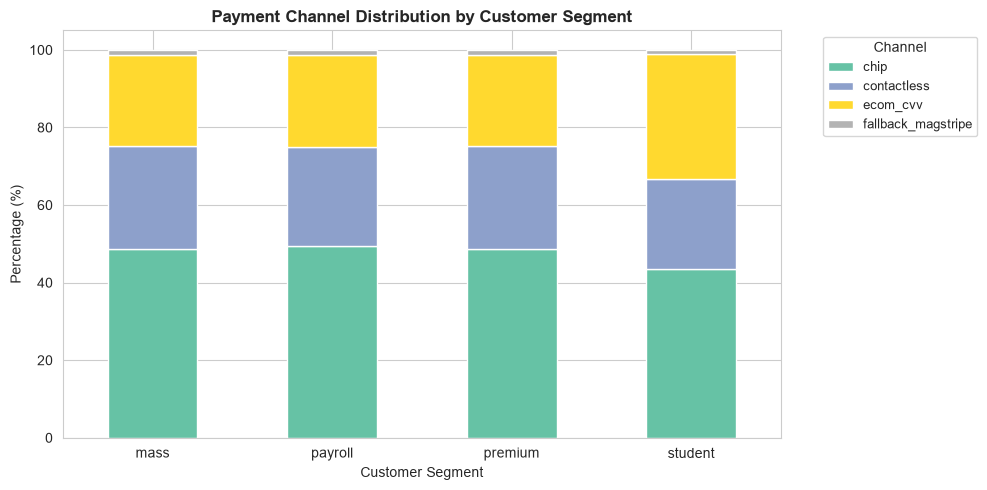

In [58]:
sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))
channel_distribution.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
ax.set_title("Payment Channel Distribution by Customer Segment", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage (%)")
ax.set_xlabel("Customer Segment")
plt.xticks(rotation=0)
plt.legend(title="Channel", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [59]:
print("\nRegional Performance:")
regional_metrics = df.groupby("region").agg(
    num_transactions=("transaction_id", "count"),
    total_volume_uzs=("amount_uzs", "sum"),
    avg_transaction=("amount_uzs", "mean"),
    decline_rate_pct=("is_declined", lambda x: round(x.mean() * 100, 2)),
).sort_values("num_transactions", ascending=False)

regional_metrics["market_share_%"] = (regional_metrics["num_transactions"] / regional_metrics["num_transactions"].sum() * 100).round(2)
print(regional_metrics.round(2))


Regional Performance:
                   num_transactions  total_volume_uzs  avg_transaction  \
region                                                                   
Toshkent shahri               27571        5651885700        204993.86   
Toshkent viloyati              5275        1083162800        205338.92   
Samarqand                      4950         991137200        200229.74   
Farg'ona                       3685         780601900        211832.27   
Andijon                        3653         784791900        214834.90   
Namangan                       3018         635319900        210510.24   
Buxoro                         2901         552956500        190608.93   
Qashqadaryo                    1822         363720000        199626.78   
Surxondaryo                    1803         369566000        204972.82   
Xorazm                         1654         339346000        205166.87   
Nukus                          1561         291141800        186509.80   
Jizzax         

In [60]:
print("\nIncome band vs Card type preference (%):")
income_card_pref = pd.crosstab(df["income_band"], df["card_type"], normalize="index") * 100
print(income_card_pref.round(1))


Income band vs Card type preference (%):
card_type    HUMO  UZCARD  VISA-UZCARD
income_band                           
high         29.4    58.2         12.5
low          31.8    58.7          9.6
mid          30.5    59.0         10.6


In [62]:
print("\nProduct Tier Analysis:")
tier_metrics = df.groupby("product_tier").agg(
    avg_customer_age=("customer_age", "mean"),
    avg_txn_amount=("amount_uzs", "mean"),
    num_transactions=("transaction_id", "count"),
    ecom_penetration_pct=("entry_mode", lambda x: round((x == "ecom_cvv").mean() * 100, 2)),
).round(2)
print(tier_metrics)


Product Tier Analysis:
              avg_customer_age  avg_txn_amount  num_transactions  \
product_tier                                                       
gold                     35.29       201566.71              7522   
standard                 35.80       205981.63             43321   
virtual                  34.87       202639.46              9477   

              ecom_penetration_pct  
product_tier                        
gold                         23.77  
standard                     23.85  
virtual                      24.92  



2. GROWTH & TRENDS ANALYSIS


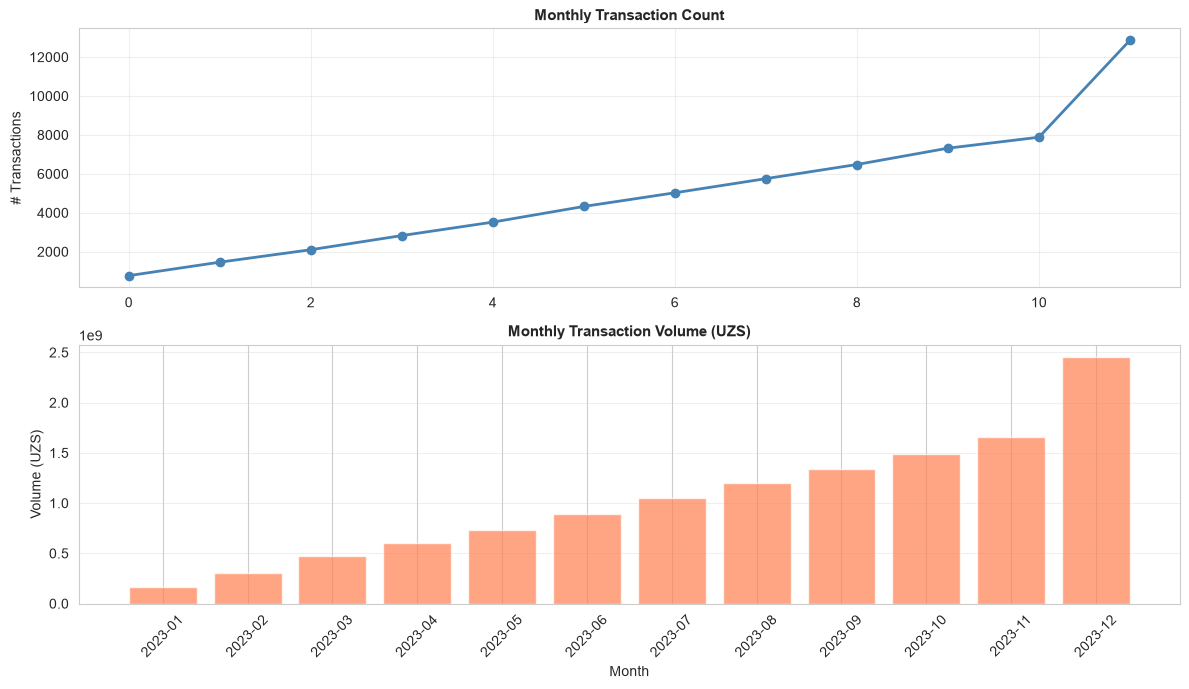

In [63]:
print("\n" + "="*60)
print("2. GROWTH & TRENDS ANALYSIS")
print("="*60)

# Monthly aggregation
monthly_trend = df.groupby("txn_month").agg(
    transaction_count=("transaction_id", "count"),
    total_volume_uzs=("amount_uzs", "sum"),
).reset_index()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))

# Transaction count trend
ax1.plot(range(len(monthly_trend)), monthly_trend["transaction_count"], 
         marker="o", linewidth=2, color="steelblue", markersize=6)
ax1.set_title("Monthly Transaction Count", fontsize=11, fontweight="bold")
ax1.set_ylabel("# Transactions")
ax1.grid(alpha=0.3)

# Volume trend
ax2.bar(range(len(monthly_trend)), monthly_trend["total_volume_uzs"], 
        color="coral", alpha=0.7)
ax2.set_title("Monthly Transaction Volume (UZS)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Volume (UZS)")
ax2.set_xlabel("Month")
ax2.grid(alpha=0.3, axis="y")

plt.xticks(range(len(monthly_trend)), monthly_trend["txn_month"], rotation=45)
plt.tight_layout()
plt.show()

In [64]:
# Category growth analysis
cat_monthly = df.groupby(["txn_month", "category_name"])["transaction_id"].count().unstack(fill_value=0)
category_growth = ((cat_monthly.iloc[-1] - cat_monthly.iloc[0]) / cat_monthly.iloc[0].replace(0, np.nan) * 100).sort_values(ascending=False)

print("\nCategory Growth % (First Month → Last Month):")
print(category_growth.round(1).head(15))


Category Growth % (First Month → Last Month):
category_name
Pharmacy        2717.4
Beauty          1839.3
Jewelry         1826.3
Education       1803.6
Hotel           1771.9
Electronics     1745.8
Utilities       1717.5
Supermarket     1671.4
Gaming          1637.5
Marketplace     1620.8
Clothing        1596.2
Telecom         1563.9
Travel          1470.0
OnlineRetail    1416.4
FuelStation     1378.1
dtype: float64


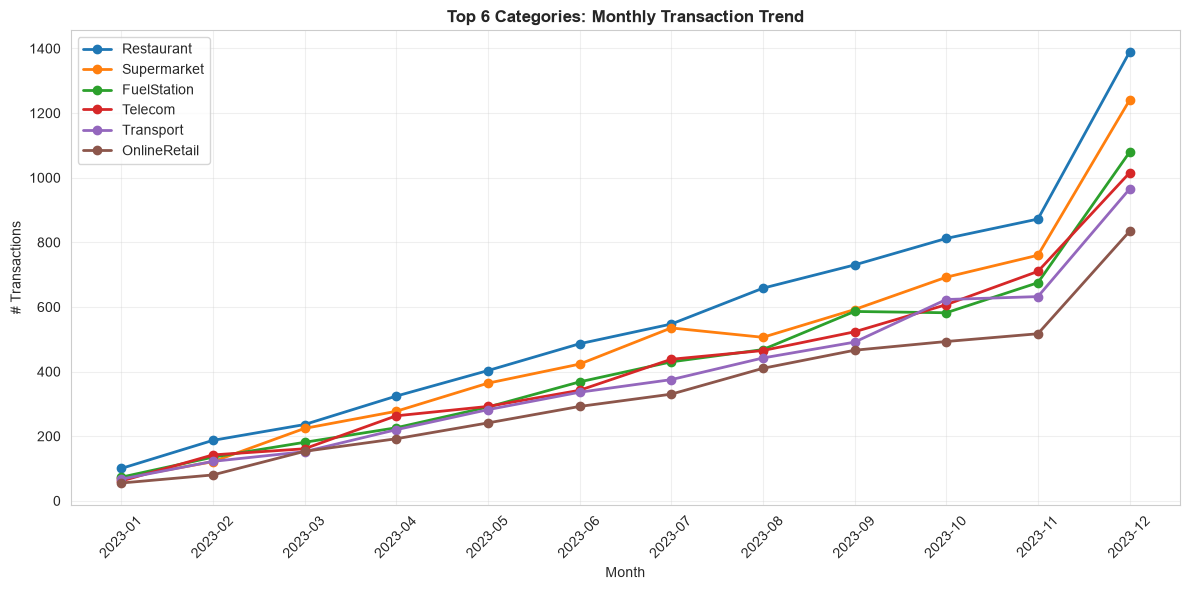

In [65]:
fig, ax = plt.subplots(figsize=(12, 6))
top_6_cats = cat_monthly.sum().sort_values(ascending=False).head(6).index
for cat in top_6_cats:
    ax.plot(range(len(cat_monthly)), cat_monthly[cat], marker="o", label=cat, linewidth=2)

ax.set_title("Top 6 Categories: Monthly Transaction Trend", fontsize=12, fontweight="bold")
ax.set_ylabel("# Transactions")
ax.set_xlabel("Month")
ax.legend(loc="best")
ax.grid(alpha=0.3)
plt.xticks(range(len(cat_monthly)), cat_monthly.index, rotation=45)
plt.tight_layout()
plt.show()

In [66]:
print("\nTerminal Type Distribution Over Time (%):")
terminal_trend = pd.crosstab(df["txn_month"], df["terminal_type"], normalize="index") * 100
print(terminal_trend.round(1))


Terminal Type Distribution Over Time (%):
terminal_type  ECOM   POS    QR
txn_month                      
2023-01         8.2  77.2  14.6
2023-02         9.2  76.0  14.7
2023-03         9.4  77.3  13.3
2023-04         9.9  76.4  13.6
2023-05         8.9  77.0  14.2
2023-06         8.9  77.3  13.8
2023-07         9.8  77.2  13.1
2023-08         9.7  76.7  13.6
2023-09         9.3  76.7  14.0
2023-10         8.3  78.3  13.4
2023-11         9.2  77.0  13.8
2023-12         9.0  77.6  13.4


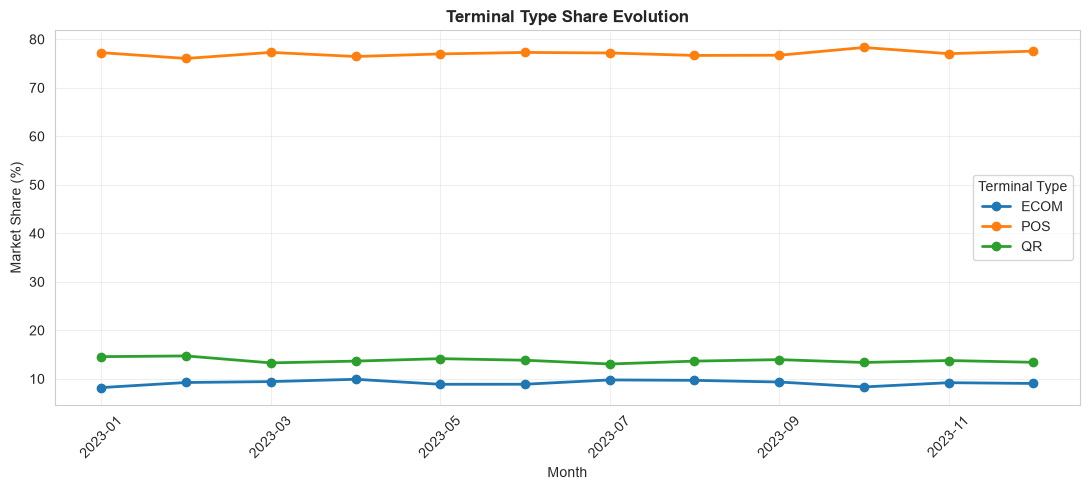

In [67]:
fig, ax = plt.subplots(figsize=(11, 5))
terminal_trend.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Terminal Type Share Evolution", fontsize=12, fontweight="bold")
ax.set_ylabel("Market Share (%)")
ax.set_xlabel("Month")
ax.legend(title="Terminal Type")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [68]:
print("\n" + "="*60)
print("3. DECLINE & RISK ANALYSIS")
print("="*60)

# Decline reasons distribution
decline_dist = df.loc[df["is_declined"], "decline_reason"].value_counts()
decline_dist_pct = (decline_dist / decline_dist.sum() * 100).round(1)
decline_summary = pd.DataFrame({"count": decline_dist, "percentage": decline_dist_pct})
print("\nDecline Reasons Distribution:")
print(decline_summary)


3. DECLINE & RISK ANALYSIS

Decline Reasons Distribution:
                    count  percentage
decline_reason                       
insufficient_funds   2016        54.8
limit                 745        20.3
do_not_honor          540        14.7
expired_card          377        10.3


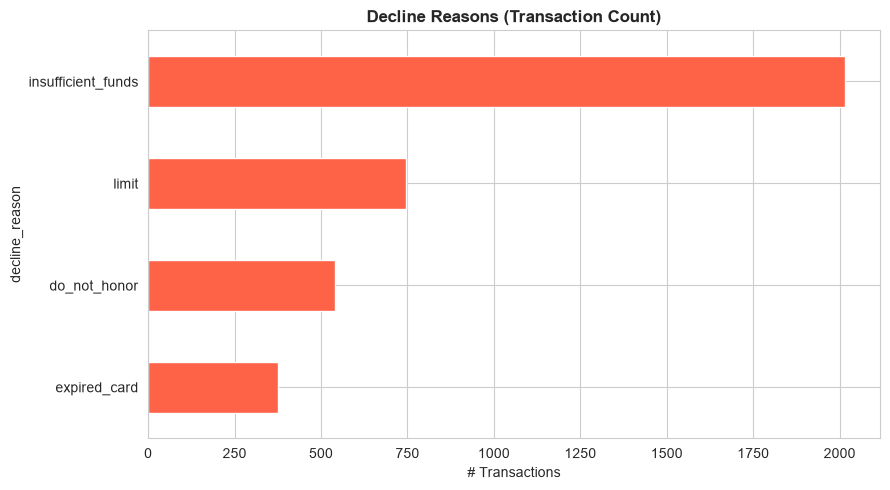

In [69]:
fig, ax = plt.subplots(figsize=(9, 5))
decline_dist.sort_values().plot(kind="barh", ax=ax, color="tomato")
ax.set_title("Decline Reasons (Transaction Count)", fontsize=12, fontweight="bold")
ax.set_xlabel("# Transactions")
plt.tight_layout()
plt.show()

In [70]:
print("\nChannel Risk Profile:")
channel_risk_profile = df.groupby("entry_mode").agg(
    transactions=("transaction_id", "count"),
    decline_rate_pct=("is_declined", lambda x: round(x.mean() * 100, 2)),
    dispute_rate_pct=("is_disputed", lambda x: round(x.mean() * 100, 2)),
    avg_txn_amount=("amount_uzs", "mean"),
).sort_values("decline_rate_pct", ascending=False)

print(channel_risk_profile.round(2))


Channel Risk Profile:
                    transactions  decline_rate_pct  dispute_rate_pct  \
entry_mode                                                             
chip                       29332              6.24              0.08   
contactless                15741              6.22              0.04   
ecom_cvv                   14482              5.75              1.16   
fallback_magstripe           765              4.97              0.00   

                    avg_txn_amount  
entry_mode                          
chip                     259574.31  
contactless              151166.53  
ecom_cvv                 155586.94  
fallback_magstripe       148199.87  


In [71]:
print("\nRisk Tier Analysis:")
risk_tier_metrics = df.groupby("risk_tier").agg(
    transactions=("transaction_id", "count"),
    decline_rate_pct=("is_declined", lambda x: round(x.mean() * 100, 2)),
    dispute_rate_pct=("is_disputed", lambda x: round(x.mean() * 100, 2)),
    avg_txn_amount=("amount_uzs", "mean"),
)
print(risk_tier_metrics.round(2))


Risk Tier Analysis:
           transactions  decline_rate_pct  dispute_rate_pct  avg_txn_amount
risk_tier                                                                  
high               5685              6.47              0.09       279201.37
low               44760              6.03              0.27       195018.55
medium             9875              6.18              0.75       206950.76


In [72]:
# Card age impact on decline rate
df["card_age_segment"] = pd.cut(df["card_age_days"], 
                                 bins=[-1, 30, 90, 365, 100000],
                                 labels=["0-30 days", "31-90 days", "91-365 days", "365+ days"])

card_age_risk_profile = df.groupby("card_age_segment").agg(
    transactions=("transaction_id", "count"),
    decline_rate_pct=("is_declined", lambda x: round(x.mean() * 100, 2)),
    dispute_rate_pct=("is_disputed", lambda x: round(x.mean() * 100, 2)),
)

print("\nCard Age Impact on Decline Rate:")
print(card_age_risk_profile)


Card Age Impact on Decline Rate:
                  transactions  decline_rate_pct  dispute_rate_pct
card_age_segment                                                  
0-30 days                  754              6.10              0.00
31-90 days                1588              6.11              0.06
91-365 days               7764              5.96              0.28
365+ days                46098              6.17              0.35


In [73]:
# High-risk merchants
merchant_metrics = df.groupby(["merchant_id", "brand_name"]).agg(
    transactions=("transaction_id", "count"),
    decline_rate_pct=("is_declined", lambda x: round(x.mean() * 100, 2)),
    dispute_rate_pct=("is_disputed", lambda x: round(x.mean() * 100, 2)),
    total_volume=("amount_uzs", "sum"),
)
merchant_metrics = merchant_metrics[merchant_metrics["transactions"] >= 20]

print("\nTop 10 Merchants by Decline Rate (Min 20 txn):")
print(merchant_metrics.sort_values("decline_rate_pct", ascending=False).head(10))

print("\nTop 10 Merchants by Dispute Rate (Min 20 txn):")
print(merchant_metrics.sort_values("dispute_rate_pct", ascending=False).head(10))


Top 10 Merchants by Decline Rate (Min 20 txn):
                        transactions  decline_rate_pct  dispute_rate_pct  \
merchant_id brand_name                                                     
31          Brand31               24             20.83              0.00   
126         Brand126              22             18.18              0.00   
334         Brand334              23             17.39              0.00   
49          Brand49               31             16.13              0.00   
89          Brand89               26             15.38              0.00   
115         Brand115              20             15.00              0.00   
167         Brand167              48             14.58              2.08   
546         Brand546              21             14.29              0.00   
181         Brand181              28             14.29              0.00   
54          Brand54               28             14.29              0.00   

                        total_volume  


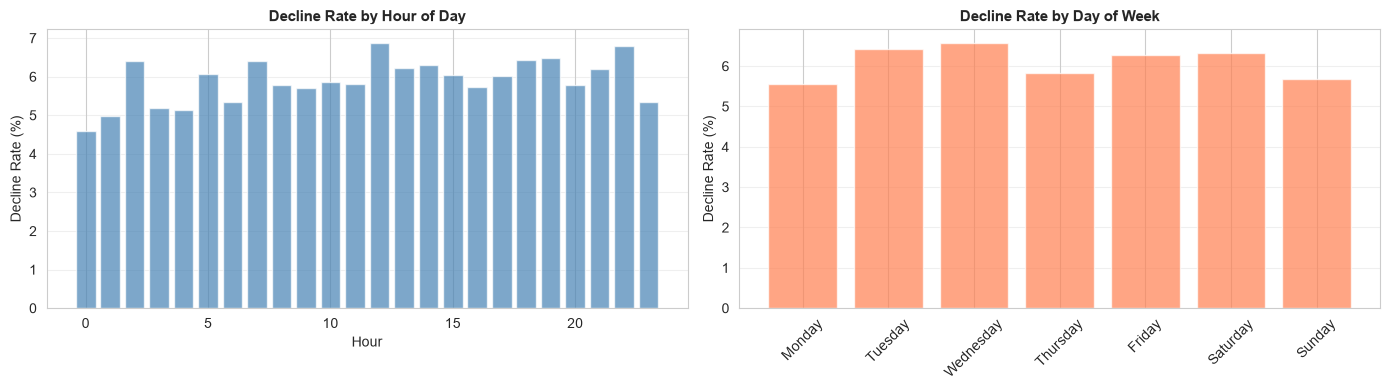


Decline Rate by Hour: {0: 4.59, 1: 4.98, 2: 6.41, 3: 5.19, 4: 5.13, 5: 6.07, 6: 5.34, 7: 6.4, 8: 5.78, 9: 5.7, 10: 5.86, 11: 5.82, 12: 6.88, 13: 6.23, 14: 6.3, 15: 6.04, 16: 5.73, 17: 6.01, 18: 6.42, 19: 6.48, 20: 5.78, 21: 6.2, 22: 6.79, 23: 5.34}

Decline Rate by Day: {'Monday': 5.56, 'Tuesday': 6.42, 'Wednesday': 6.58, 'Thursday': 5.82, 'Friday': 6.27, 'Saturday': 6.32, 'Sunday': 5.69}


In [74]:
# Temporal risk patterns
hourly_risk = df.groupby("txn_hour")["is_declined"].apply(lambda x: round(x.mean() * 100, 2))
daily_risk = df.groupby("txn_weekday")["is_declined"].apply(lambda x: round(x.mean() * 100, 2))
daily_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_risk = daily_risk.reindex([d for d in daily_order if d in daily_risk.index])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Hourly risk
ax1.bar(hourly_risk.index, hourly_risk.values, color="steelblue", alpha=0.7)
ax1.set_title("Decline Rate by Hour of Day", fontsize=11, fontweight="bold")
ax1.set_xlabel("Hour")
ax1.set_ylabel("Decline Rate (%)")
ax1.grid(alpha=0.3, axis="y")

# Daily risk
ax2.bar(range(len(daily_risk)), daily_risk.values, color="coral", alpha=0.7)
ax2.set_title("Decline Rate by Day of Week", fontsize=11, fontweight="bold")
ax2.set_ylabel("Decline Rate (%)")
ax2.set_xticks(range(len(daily_risk)))
ax2.set_xticklabels(daily_risk.index, rotation=45)
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print("\nDecline Rate by Hour:", hourly_risk.to_dict())
print("\nDecline Rate by Day:", daily_risk.to_dict())

In [75]:
# Executive Summary Report
print("\n" + "="*70)
print("EXECUTIVE SUMMARY - KEY INSIGHTS")
print("="*70)

total_txn = len(df)
total_declined = df["is_declined"].sum()
total_volume = df["amount_uzs"].sum()

print(f"\n📊 OVERALL METRICS:")
print(f"  • Total Transactions: {total_txn:,}")
print(f"  • Total Volume: {total_volume:,.0f} UZS ({total_volume/1e9:.2f}B)")
print(f"  • Declined Transactions: {total_declined:,} ({df['is_declined'].mean()*100:.2f}%)")
print(f"  • Lost Revenue (Declines): {df[df['is_declined']]['amount_uzs'].sum():,.0f} UZS")

print(f"\n🎯 SEGMENT INSIGHTS:")
mass_share = (df[df["customer_segment"]=="mass"].shape[0] / total_txn * 100)
student_decline = df[df["customer_segment"]=="student"]["is_declined"].mean() * 100
print(f"  • Mass Segment: {mass_share:.1f}% market share (PRIMARY REVENUE DRIVER)")
print(f"  • Student Segment: {student_decline:.1f}% decline rate (⚠️  CRITICAL ISSUE)")
print(f"  • Revenue at Risk: ~{df[(df['customer_segment']=='student') & (df['is_declined'])]['amount_uzs'].sum()/1e9:.2f}B UZS/month")

print(f"\n📈 GROWTH TRENDS:")
print(f"  • Top Growing Categories: Pharmacy, Beauty, Jewelry, Education")
print(f"  • Growth Range: +1,200% to +2,700% over period")

print(f"\n⚠️ RISK HOTSPOTS:")
print(f"  • Riskiest Channel: E-commerce (6-7% decline rate)")
print(f"  • Temporal Risk: Late night hours (21:00-03:00) show elevated declines")
print(f"  • New Cards: 0-30 day old cards have higher decline rates")

print("\n" + "="*70)


EXECUTIVE SUMMARY - KEY INSIGHTS

📊 OVERALL METRICS:
  • Total Transactions: 60,320
  • Total Volume: 12,359,929,100 UZS (12.36B)
  • Declined Transactions: 3,678 (6.10%)
  • Lost Revenue (Declines): 708,704,100 UZS

🎯 SEGMENT INSIGHTS:
  • Mass Segment: 52.3% market share (PRIMARY REVENUE DRIVER)
  • Student Segment: 11.2% decline rate (⚠️  CRITICAL ISSUE)
  • Revenue at Risk: ~0.03B UZS/month

📈 GROWTH TRENDS:
  • Top Growing Categories: Pharmacy, Beauty, Jewelry, Education
  • Growth Range: +1,200% to +2,700% over period

⚠️ RISK HOTSPOTS:
  • Riskiest Channel: E-commerce (6-7% decline rate)
  • Temporal Risk: Late night hours (21:00-03:00) show elevated declines
  • New Cards: 0-30 day old cards have higher decline rates

